# Bab 7 - Cara Memvisualisasikan Jaringan Saraf: Dalam Pikiran dan di Atas Kertas

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Sampai saat ini kita telah mempelajari banyak komponen (bobot, layer, delta, backpropagation). Bab 7 berfokus menyatukan semuanya ke dalam sebuah **gambaran mental (mental picture)** yang mudah dipikirkan dan dikomunikasikan:

1. **Menyederhanakan notasi:** alih-alih menggambar setiap neuron dan koneksi satu per satu, gambarlah setiap **layer sebagai sebuah vektor ("variabel")** dan setiap **matriks bobot sebagai tanda panah** di antara layer. Layer dinamai `layer_0, layer_1, ...` dan matriks bobot `weights_0_1, weights_1_2, ...`.
2. **Huruf untuk matematika:** tulis seluruh alur forward pass sebagai `layer_2 = relu(layer_0 . W01) . W12` dalam satu baris.
3. **Menghubungkan variabel-variabel:** setiap kotak (layer) hanyalah sebuah vektor angka, setiap panah adalah sebuah matriks; bayangkan bagaimana data mengalir dari kiri ke kanan dan bagaimana delta mengalir dari kanan ke kiri.
4. **Semuanya berdampingan:** gambaran yang sama berlaku untuk berapa pun jumlah input/output; ini juga memberi tahu Anda **bentuk (shapes)** yang harus cocok.
5. **Konsep kunci - ringkasan korelasi (correlation summarization):** jaringan saraf *mencari korelasi antara input layer dan output layer* lalu **merangkumnya** di dalam bobot-bobotnya. Bobot bernilai positif untuk input yang berkorelasi positif dengan target, negatif untuk yang berkorelasi negatif, dan mendekati nol ketika tidak ada korelasi.
6. **Mengapa jaringan dua layer sebelumnya gagal** terlihat jelas dalam gambaran ini: jaringan tersebut hanya dapat melihat korelasi *langsung*. Hidden layer menciptakan "korelasi" perantara (fitur) yang dapat digunakan oleh output layer.
7. **Dot product sebagai kesamaan (similarity):** penjumlahan berbobot membandingkan input dengan vektor bobot, sehingga vektor bobot bertindak seperti sebuah **templat**: output bernilai tinggi ketika input menyerupai templat tersebut.

> Bab ini sebagian besar bersifat konseptual di dalam buku. Notebook ini mereproduksi cuplikan kode numpy dan menambahkan visualisasi (yang ditandai dengan jelas sebagai "ekstensi") dari gagasan-gagasan tersebut.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(1)

## 1. Jaringan dalam gambaran yang disederhanakan
`layer_0` (3 input) -> `weights_0_1` (3 x 4) -> `layer_1` (4 hidden) -> `weights_1_2` (4 x 1) -> `layer_2` (1 output).
Bentuk matriks harus berantai: jumlah **kolom** pada satu matriks sama dengan jumlah **baris** pada matriks berikutnya.


In [2]:
streetlights = np.array([[1, 0, 1], [0, 1, 1], [0, 0, 1], [1, 1, 1]])
walk_vs_stop = np.array([[1, 1, 0, 0]]).T

weights_0_1 = np.random.random((3, 4))
weights_1_2 = np.random.random((4, 1))

layer_0 = streetlights[0:1]               # bentuk (1, 3)
layer_1 = layer_0.dot(weights_0_1)        # bentuk (1, 4)
layer_2 = layer_1.dot(weights_1_2)        # bentuk (1, 1)
print('layer_0', layer_0.shape, '-> weights_0_1', weights_0_1.shape, '-> layer_1', layer_1.shape,
      '-> weights_1_2', weights_1_2.shape, '-> layer_2', layer_2.shape)

layer_0 (1, 3) -> weights_0_1 (3, 4) -> layer_1 (1, 4) -> weights_1_2 (4, 1) -> layer_2 (1, 1)


### Ekstensi: menggambar gambaran mental


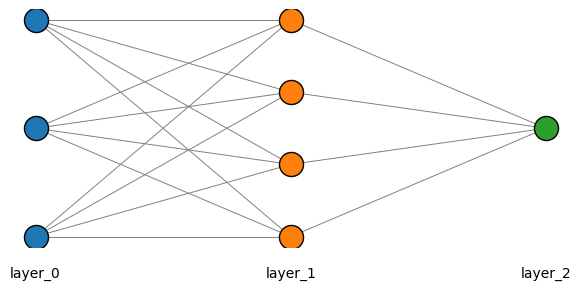

In [3]:
def draw_network(sizes, names, ax):
    xs = np.linspace(0, 1, len(sizes))
    for x, n, name in zip(xs, sizes, names):
        ys = np.linspace(0.15, 0.85, n) if n > 1 else [0.5]
        ax.scatter([x] * n, ys, s=300, edgecolor='k', zorder=3)
        ax.text(x, 0.02, name, ha='center')
    for a in range(len(sizes) - 1):
        ya = np.linspace(0.15, 0.85, sizes[a]) if sizes[a] > 1 else [0.5]
        yb = np.linspace(0.15, 0.85, sizes[a + 1]) if sizes[a + 1] > 1 else [0.5]
        for y1 in ya:
            for y2 in yb:
                ax.plot([xs[a], xs[a + 1]], [y1, y2], color='grey', lw=0.7, zorder=1)
    ax.axis('off')

fig, ax = plt.subplots(figsize=(6, 3))
draw_network([3, 4, 1], ['layer_0', 'layer_1', 'layer_2'], ax)
plt.tight_layout(); plt.show()

## 2. Ringkasan korelasi (Correlation summarization)
Latih jaringan **dua layer** (tanpa hidden layer) pada dataset di mana target benar-benar berkorelasi dengan input, lalu bandingkan setiap bobot yang dipelajari dengan korelasi mentah antara input tersebut dan target.
Di sini target bernilai "jalan" (walk) hanya ketika lampu **tengah** menyala (lampu pertama hanyalah noise).


In [4]:
lights = np.array([[1, 0, 1], [0, 1, 1], [0, 0, 1], [1, 1, 1], [0, 1, 1], [1, 0, 1]])
walk = np.array([[0, 1, 0, 1, 1, 0]]).T

w = 2 * np.random.random((3, 1)) - 1
for it in range(200):
    delta = lights.dot(w) - walk
    w -= 0.1 * lights.T.dot(delta)

print('learned weights:        ', np.round(w.ravel(), 3))
corr = [np.corrcoef(lights[:, j], walk.ravel())[0, 1] if lights[:, j].std() > 0 else np.nan for j in range(3)]
print('correlation with target:', np.round(corr, 3), '  (third light is always on: no information)')

learned weights:         [-0.  1.  0.]
correlation with target: [-0.333  1.       nan]   (third light is always on: no information)


Lampu tengah berkorelasi sempurna dengan target (korelasi 1.0), sehingga bobotnya bergerak mendekati 1. Lampu pertama hanya memiliki korelasi negatif yang lemah (-0.33) dan, karena lampu tengah telah menjelaskan target sepenuhnya, bobotnya bergerak mendekati 0. Lampu ketiga selalu menyala, sehingga tidak membawa informasi apa pun (korelasinya tidak terdefinisi) dan juga mendapatkan bobot sekitar 0.
Inilah yang disebut **ringkasan korelasi (correlation summarization)**: bobot-bobot menyimpan ringkasan mengenai input mana yang memprediksi output.


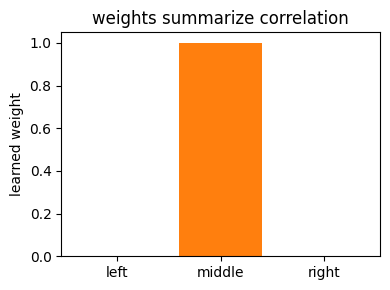

In [5]:
plt.figure(figsize=(4, 3))
plt.bar(['left', 'middle', 'right'], w.ravel(), color=['C0', 'C1', 'C2'])
plt.ylabel('learned weight'); plt.title('weights summarize correlation')
plt.tight_layout(); plt.show()

## 3. Mengapa jaringan yang lebih dalam dapat menemukan korelasi *tidak langsung*
Gunakan kembali data mirip-XOR dari Bab 6 (jalan ketika tepat satu dari dua lampu pertama menyala). Tidak ada input yang berkorelasi langsung dengan target:


In [6]:
sl = np.array([[1, 0, 1], [0, 1, 1], [0, 0, 1], [1, 1, 1]])
wv = np.array([[1, 1, 0, 0]]).T
for j, name in enumerate(['left', 'middle', 'right']):
    col = sl[:, j]
    c = np.corrcoef(col, wv.ravel())[0, 1] if col.std() > 0 else float('nan')
    print(f'{name:6s} light vs target correlation = {c:+.2f}')

left   light vs target correlation = +0.00
middle light vs target correlation = +0.00
right  light vs target correlation = +nan


Setiap lampu memiliki korelasi 0 (atau bernilai konstan) dengan target, sehingga jaringan dua layer tidak mendapatkan apa-apa. Hidden layer dapat membangun **fitur-fitur baru** (misalnya "lampu kiri menyala dan lampu tengah padam") yang *memang* berkorelasi dengan target.
Backpropagation adalah proses di mana output layer memberi tahu hidden layer "saya menginginkan lebih banyak fitur ini", sehingga *menciptakan* korelasi untuk ditemukan oleh hidden layer.

## 4. Ekstensi: bobot sebagai templat (dot product = kesamaan)
Untuk angka-angka MNIST, jaringan linear dari 784 piksel ke 10 output memiliki satu vektor bobot per digit. Memplot masing-masing sebagai gambar 28x28 memperlihatkan apa yang dianggap jaringan sebagai "bukti" untuk digit tersebut.


In [7]:
import gzip
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA = Path('..') / 'data' / 'mnist'

def load_images(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=16).reshape(-1, 28 * 28)

def load_labels(name):
    with gzip.open(DATA / name, 'rb') as fh:
        return np.frombuffer(fh.read(), np.uint8, offset=8)

def one_hot(labels, n=10):
    out = np.zeros((len(labels), n))
    out[np.arange(len(labels)), labels] = 1
    return out

# buku ini melatih pada 1.000 gambar pertama dan menguji pada seluruh 10.000 gambar uji
x_train = load_images('train-images-idx3-ubyte.gz')[:1000] / 255.0
y_train_raw = load_labels('train-labels-idx1-ubyte.gz')[:1000]
y_train = one_hot(y_train_raw)
x_test = load_images('t10k-images-idx3-ubyte.gz') / 255.0
y_test_raw = load_labels('t10k-labels-idx1-ubyte.gz')
y_test = one_hot(y_test_raw)
print('train:', x_train.shape, y_train.shape, ' test:', x_test.shape, y_test.shape)

train: (1000, 784) (1000, 10)  test: (10000, 784) (10000, 10)


train accuracy 0.922   test accuracy 0.807


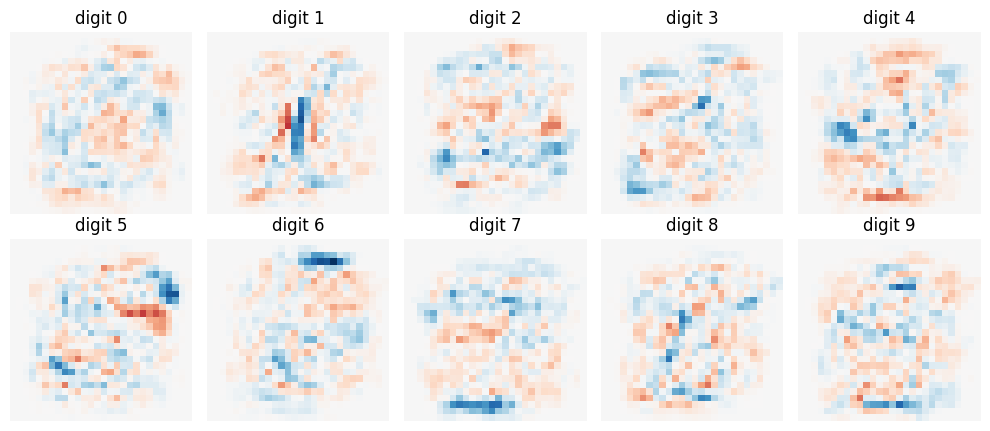

In [8]:
W = np.zeros((784, 10))
for it in range(800):
    err = x_train.dot(W) - y_train
    W -= 0.02 * x_train.T.dot(err) / len(x_train)

acc_train = np.mean(x_train.dot(W).argmax(1) == y_train_raw)
acc_test = np.mean(x_test.dot(W).argmax(1) == y_test_raw)
print(f'train accuracy {acc_train:.3f}   test accuracy {acc_test:.3f}')

fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for d, ax in enumerate(axes.ravel()):
    ax.imshow(W[:, d].reshape(28, 28), cmap='RdBu', vmin=-W.max(), vmax=W.max())
    ax.set_title(f'digit {d}'); ax.axis('off')
plt.tight_layout(); plt.show()

Area merah/biru menunjukkan piksel yang memberikan bukti positif/negatif untuk setiap digit. Prediksi untuk gambar baru adalah hasil dot product dengan setiap templat, yang bernilai tinggi saat gambar bertumpang tindih dengan area positif templat tersebut. Ini adalah
interpretasi "kesamaan (similarity)" dari penjumlahan berbobot, dan ini juga memperlihatkan *mengapa satu layer tunggal memiliki keterbatasan*: ia hanya dapat menggunakan satu templat per kelas.

## Poin-poin kunci
* Gambarlah layer sebagai vektor dan bobot sebagai matriks; pastikan bentuk matriks berantai dengan benar.
* Jaringan melakukan **ringkasan korelasi (correlation summarization)**: bobot mencatat input mana yang naik dan turun bersamaan dengan target.
* Tanpa hidden layer hanya korelasi *langsung* yang dapat ditemukan; hidden layer dan backpropagation menciptakan serta menemukan korelasi *tidak langsung*.
* Vektor bobot berfungsi sebagai templat; dot product mengukur seberapa mirip input terhadap templat tersebut.
